# Prosperity Gap in Venezuela (1981-2006) in Latin American Perspective

**Author:** _Your Name_ · **Tools:** Python (pandas, matplotlib) · **Source:** [Poverty and Inequality Platform (PIP), World Bank](https://pip.worldbank.org/)

## Research question
How did the prosperity gap in Venezuela evolve between 1981 and 2006, and how does it compare with the rest of Latin America?

## What the indicator measures
The **Prosperity Gap** is the average factor by which people's incomes would need to be multiplied to reach the World Bank's prosperity standard (about US$25 a day in 2017 PPP). **A higher value means the population is further from that standard.** For example, a value of 10 means incomes would need to increase tenfold, on average.

> **Note:** the file labels the unit as _"Percentage"_, but the official definition of the indicator is a multiplicative factor. This analysis treats it as a factor.

## Contents
1. Loading and inspecting the data
2. Cleaning
3. Venezuela: evolution 1981-2006
4. Venezuela compared with Latin America
5. Conclusions and limitations

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

RAW = Path("../data/raw/PV_PI_PG.csv")
PROCESSED = Path("../data/processed/prosperity_gap_clean.csv")
IMAGES = Path("../images")
PROCESSED.parent.mkdir(parents=True, exist_ok=True)
IMAGES.mkdir(exist_ok=True)

RED, GREY = "#C0392B", "#9AA0A6"

## 1. Loading and inspecting the data

In [2]:
df_raw = pd.read_csv(RAW)
print(f"Rows: {df_raw.shape[0]:,} | Columns: {df_raw.shape[1]}")
df_raw.head(3)

Rows: 5,424 | Columns: 39


,STRUCTURE,STRUCTURE_ID,ACTION,FREQ,REF_AREA,INDICATOR,URBANIZATION,WELFARE_TYPE,POVERTY_LINE,INCOME_GROUP,UNIT_MEASURE,TIME_PERIOD,OBS_VALUE,AGG_METHOD,UNIT_TYPE,DECIMALS,DATABASE_ID,TIME_FORMAT,UNIT_MULT,OBS_STATUS,OBS_CONF,COMP_SPELL,DISTRIBUTION_TYPE,FREQ_LABEL,REF_AREA_LABEL,INDICATOR_LABEL,URBANIZATION_LABEL,WELFARE_TYPE_LABEL,POVERTY_LINE_LABEL,INCOME_GROUP_LABEL,UNIT_MEASURE_LABEL,AGG_METHOD_LABEL,UNIT_TYPE_LABEL,DECIMALS_LABEL,DATABASE_ID_LABEL,TIME_FORMAT_LABEL,UNIT_MULT_LABEL,OBS_STATUS_LABEL,OBS_CONF_LABEL
0,dataflow,WB.DEC.DG:DF_PIP(1.0.0),I,A,AGO,PV_PI_PG,_T,C,_Z,_T,PT,2000,9.6092,W_AVG,RATIO,2,WB_PIP,602,0,A,PU,2000,micro,Annual,Angola,Prosperity Gap,Total,Consumption,Not Applicable,All income groups,Percentage,Weighted Average,Ratio,Two,Poverty and Inequality Platform (PIP),CCYY,Units,Normal value,Public
1,dataflow,WB.DEC.DG:DF_PIP(1.0.0),I,A,AGO,PV_PI_PG,_T,C,_Z,_T,PT,2008,6.8388,W_AVG,RATIO,2,WB_PIP,602,0,A,PU,2008,micro,Annual,Angola,Prosperity Gap,Total,Consumption,Not Applicable,All income groups,Percentage,Weighted Average,Ratio,Two,Poverty and Inequality Platform (PIP),CCYY,Units,Normal value,Public
2,dataflow,WB.DEC.DG:DF_PIP(1.0.0),I,A,AGO,PV_PI_PG,_T,C,_Z,_T,PT,2018,10.9642,W_AVG,RATIO,2,WB_PIP,602,0,A,PU,2018,micro,Annual,Angola,Prosperity Gap,Total,Consumption,Not Applicable,All income groups,Percentage,Weighted Average,Ratio,Two,Poverty and Inequality Platform (PIP),CCYY,Units,Normal value,Public


In [3]:
# Overview
print("Areas (countries + aggregates):", df_raw["REF_AREA"].nunique())
print("Years:", df_raw["TIME_PERIOD"].min(), "-", df_raw["TIME_PERIOD"].max())
print("Missing values in OBS_VALUE:", df_raw["OBS_VALUE"].isna().sum())

# Columns with a single value carry no information
constant_cols = [c for c in df_raw.columns if df_raw[c].nunique(dropna=False) == 1]
print(f"\n{len(constant_cols)} of {df_raw.shape[1]} columns contain a single value.")

Areas (countries + aggregates): 182
Years: 1963 - 2025
Missing values in OBS_VALUE: 0

29 of 39 columns contain a single value.


In [4]:
# Some "areas" are not countries but aggregates (regions, world). They have no distribution type.
raw_aggregates = df_raw[df_raw["DISTRIBUTION_TYPE"].isna()]
print("Aggregates:", raw_aggregates["REF_AREA"].nunique(), "->", sorted(raw_aggregates["REF_AREA_LABEL"].unique()))
print("Actual countries:", df_raw.loc[df_raw["DISTRIBUTION_TYPE"].notna(), "REF_AREA"].nunique())

Aggregates: 10 -> ['East Asia & Pacific', 'Eastern and Southern Africa', 'Europe & Central Asia', 'Latin America & Caribbean', 'Middle East, North Africa, Afghanistan & Pakistan', 'North America', 'South Asia', 'Sub-Saharan Africa', 'Western and Central Africa', 'World']
Actual countries: 172


In [5]:
# Welfare measurement types and urban/rural coverage
print(df_raw["WELFARE_TYPE_LABEL"].value_counts(), "\n")
print(df_raw["URBANIZATION_LABEL"].value_counts())

WELFARE_TYPE_LABEL
Combined       2836
Income         1588
Consumption    1000
Name: count, dtype: int64 

URBANIZATION_LABEL
Total         5256
Urban area     143
Rural area      25
Name: count, dtype: int64


### Finding: redundancy between measurement types
The file stores the same value under both `Income` and `Combined`. Let's verify with Venezuela.

In [6]:
ven_raw = df_raw[df_raw["REF_AREA"] == "VEN"]
comparison = ven_raw.pivot_table(index="TIME_PERIOD", columns="WELFARE_TYPE_LABEL", values="OBS_VALUE")
print("Is Income == Combined in every year?", (comparison["Income"] == comparison["Combined"]).all())
comparison

Is Income == Combined in every year? True


WELFARE_TYPE_LABEL,Combined,Income
TIME_PERIOD,,
1981,4.1352,4.1352
1987,4.3319,4.3319
1989,5.8546,5.8546
1992,5.2369,5.2369
1995,6.8266,6.8266
1998,7.5814,7.5814
1999,7.8058,7.8058
2001,7.2113,7.2113
2002,10.0100,10.0100


## 2. Cleaning

Decisions made:

| Decision | Reason |
|---|---|
| Keep only `WELFARE_TYPE = CI` (Combined) | Avoids duplicates; for Venezuela it matches `Income` |
| Keep only `URBANIZATION = _T` (Total) | National coverage; the urban/rural breakdown is very sparse |
| Separate regional aggregates from countries | Mixing them distorts rankings and averages; the Latin America aggregate is useful as a benchmark |
| Drop constant columns and repeated labels | They carry no information |
| Keep `COMP_SPELL` and `DISTRIBUTION_TYPE` | They show which observations are strictly comparable and how reliable they are |
| Rename columns to readable snake_case | Readability |

In [7]:
df = df_raw[(df_raw["WELFARE_TYPE"] == "CI") & (df_raw["URBANIZATION"] == "_T")].copy()

df = df[["REF_AREA", "REF_AREA_LABEL", "TIME_PERIOD", "OBS_VALUE", "COMP_SPELL", "DISTRIBUTION_TYPE"]]
df.columns = ["country_code", "country", "year", "prosperity_gap", "comparability_spell", "distribution_type"]
df = df.sort_values(["country_code", "year"]).reset_index(drop=True)

# Split regional aggregates (no distribution type) from countries
df_aggregates = df[df["distribution_type"].isna()].reset_index(drop=True)
df = df[df["distribution_type"].notna()].reset_index(drop=True)

# Validation checks
assert not df.duplicated(["country_code", "year"]).any(), "Duplicate country-year rows"
assert not df_aggregates.duplicated(["country_code", "year"]).any(), "Duplicate rows in aggregates"
assert df["prosperity_gap"].notna().all(), "Missing values found"

print(f"From {len(df_raw):,} rows and {df_raw.shape[1]} columns we get:")
print(f"  - Countries:  {len(df):,} rows, {df['country_code'].nunique()} countries, {df.shape[1]} columns")
print(f"  - Aggregates: {len(df_aggregates):,} rows, {df_aggregates['country_code'].nunique()} regions")

df.to_csv(PROCESSED, index=False)
df_aggregates.to_csv(PROCESSED.with_name("prosperity_gap_aggregates.csv"), index=False)
df.head()

From 5,424 rows and 39 columns we get:
  - Countries:  2,391 rows, 171 countries, 6 columns
  - Aggregates: 386 rows, 10 regions


,country_code,country,year,prosperity_gap,comparability_spell,distribution_type
0,AGO,Angola,2000,9.6092,2000,micro
1,AGO,Angola,2008,6.8388,2008,micro
2,AGO,Angola,2018,10.9642,2018,micro
3,ALB,Albania,1996,4.2094,1996,micro
4,ALB,Albania,2002,4.4293,2002 - 2012,micro


## 3. Venezuela: evolution 1981-2006

Two data-quality points to keep in mind:
- **Comparability spells (`comparability_spell`):** the World Bank groups surveys that are strictly comparable with each other. Comparing values across different spells requires caution.
- **Distribution type:** `micro` comes from household survey microdata; `group` comes from grouped data (less precise). Venezuela's 1981 and 1987 observations are `group`.

In [8]:
ven = df[df["country_code"] == "VEN"].reset_index(drop=True)
print("Observations:", len(ven), "| Range:", ven["year"].min(), "-", ven["year"].max())
ven[["year", "prosperity_gap", "comparability_spell", "distribution_type"]]

Observations: 13 | Range: 1981 - 2006


,year,prosperity_gap,comparability_spell,distribution_type
0,1981,4.1352,1981 - 1987,group
1,1987,4.3319,1981 - 1987,group
2,1989,5.8546,1989 - 1999,micro
3,1992,5.2369,1989 - 1999,micro
4,1995,6.8266,1989 - 1999,micro
5,1998,7.5814,1989 - 1999,micro
6,1999,7.8058,1989 - 1999,micro
7,2001,7.2113,2001 - 2006,micro
8,2002,10.0100,2001 - 2006,micro
9,2003,11.5333,2001 - 2006,micro


In [9]:
peak = ven.loc[ven["prosperity_gap"].idxmax()]
v1999 = ven.loc[ven["year"] == 1999, "prosperity_gap"].iloc[0]
v2006 = ven.loc[ven["year"] == 2006, "prosperity_gap"].iloc[0]
v1981 = ven.loc[ven["year"] == 1981, "prosperity_gap"].iloc[0]

print(f"Initial value (1981): {v1981:.2f}")
print(f"1999: {v1999:.2f}")
print(f"Peak ({int(peak['year'])}): {peak['prosperity_gap']:.2f}")
print(f"Last data point (2006): {v2006:.2f}")
print(f"\nChange 1999 -> {int(peak['year'])}: {peak['prosperity_gap']/v1999 - 1:+.1%}")
print(f"Change {int(peak['year'])} -> 2006: {v2006/peak['prosperity_gap'] - 1:+.1%}")

Initial value (1981): 4.14
1999: 7.81
Peak (2003): 11.53
Last data point (2006): 6.52

Change 1999 -> 2003: +47.8%
Change 2003 -> 2006: -43.5%


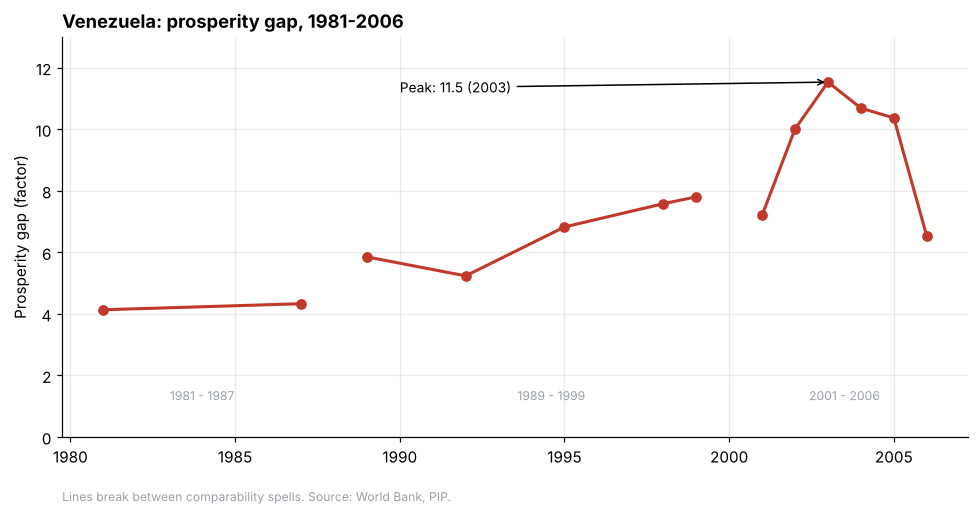

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.8))

# One line per comparability spell (the line breaks between spells)
for i, (spell, g) in enumerate(ven.groupby("comparability_spell")):
    ax.plot(g["year"], g["prosperity_gap"], marker="o", color=RED, lw=2)
    ax.text(g["year"].mean(), 1.2, spell, ha="center", fontsize=8, color=GREY)

ax.annotate(f"Peak: {peak['prosperity_gap']:.1f} ({int(peak['year'])})",
            xy=(peak["year"], peak["prosperity_gap"]),
            xytext=(1990, 11.2), arrowprops=dict(arrowstyle="->", color="black"), fontsize=9)

ax.set_title("Venezuela: prosperity gap, 1981-2006", loc="left", fontweight="bold")
ax.set_ylabel("Prosperity gap (factor)")
ax.set_xlabel("")
ax.set_ylim(0, 13)
ax.text(0, -0.16, "Lines break between comparability spells. Source: World Bank, PIP.",
        transform=ax.transAxes, fontsize=8, color=GREY)
plt.tight_layout()
plt.savefig(IMAGES / "01_venezuela_series.png", bbox_inches="tight")
plt.show()

## 4. Venezuela compared with Latin America

The comparison covers 17 countries in the region with national-level data, plus the World Bank's **Latin America & Caribbean (LAC) aggregate** as a benchmark (a population-weighted average, so Brazil and Mexico carry more weight). **Argentina does not appear** because this file has no national-coverage observations for it (its household survey is urban only).

Countries included: 17


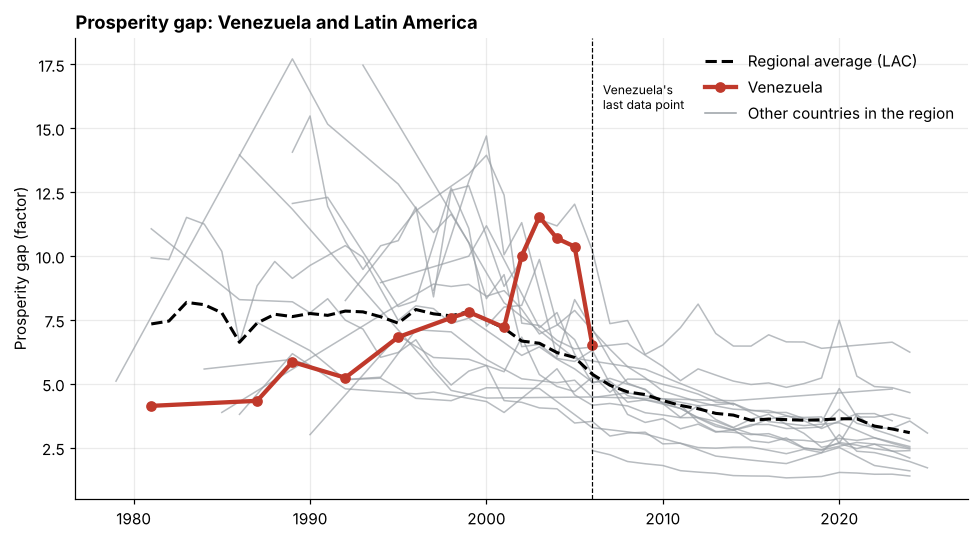

In [11]:
LATAM = ["BOL", "BRA", "CHL", "COL", "CRI", "DOM", "ECU", "SLV", "GTM", "HND",
         "MEX", "NIC", "PAN", "PRY", "PER", "URY", "VEN"]
lat = df[df["country_code"].isin(LATAM)]
print("Countries included:", lat["country_code"].nunique())

fig, ax = plt.subplots(figsize=(9, 5))
for code_, g in lat.groupby("country_code"):
    if code_ != "VEN":
        ax.plot(g["year"], g["prosperity_gap"], color=GREY, lw=1, alpha=0.7)
g = lat[lat["country_code"] == "VEN"]
lac = df_aggregates[df_aggregates["country_code"] == "LCN"]   # Latin America & Caribbean (aggregate)
ax.plot(lac["year"], lac["prosperity_gap"], color="black", lw=2, ls="--", label="Regional average (LAC)")
ax.plot(g["year"], g["prosperity_gap"], color=RED, lw=2.8, marker="o", label="Venezuela")
ax.plot([], [], color=GREY, lw=1, label="Other countries in the region")
ax.axvline(2006, color="black", ls="--", lw=0.8)
ax.text(2006.6, ax.get_ylim()[1] * 0.85, "Venezuela's\nlast data point", fontsize=8)

ax.set_title("Prosperity gap: Venezuela and Latin America", loc="left", fontweight="bold")
ax.set_ylabel("Prosperity gap (factor)")
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
plt.savefig(IMAGES / "02_venezuela_vs_latam.png", bbox_inches="tight")
plt.show()

In [12]:
# Venezuela versus the regional average (World Bank LAC aggregate) in key years
lac_s = lac.set_index("year")["prosperity_gap"]
ven_s = ven.set_index("year")["prosperity_gap"]
key_years = pd.DataFrame({"Venezuela": ven_s.loc[[1981, 1999, 2003, 2006]],
                          "LAC average": lac_s.loc[[1981, 1999, 2003, 2006]]})
key_years["Difference"] = key_years["Venezuela"] - key_years["LAC average"]
key_years.round(2)

,Venezuela,LAC average,Difference
year,,,
1981,4.14,7.34,-3.21
1999,7.81,7.82,-0.02
2003,11.53,6.59,4.95
2006,6.52,5.37,1.15


In [13]:
# Where was Venezuela in 2003, the year of its peak?
y = lat[lat["year"] == 2003].sort_values("prosperity_gap", ascending=False)
y[["country", "prosperity_gap"]].reset_index(drop=True)

,country,prosperity_gap
0,"Venezuela, RB",11.5333
1,Honduras,11.4282
2,El Salvador,9.8643
3,Colombia,7.2826
4,Ecuador,7.1952
5,Peru,6.9486
6,Panama,6.5399
7,Brazil,6.4449
8,Paraguay,5.3614
9,Dominican Republic,4.9864


Venezuela ranks 4 of 16 (1 = largest gap)
Regional average (excluding Venezuela): 7.3


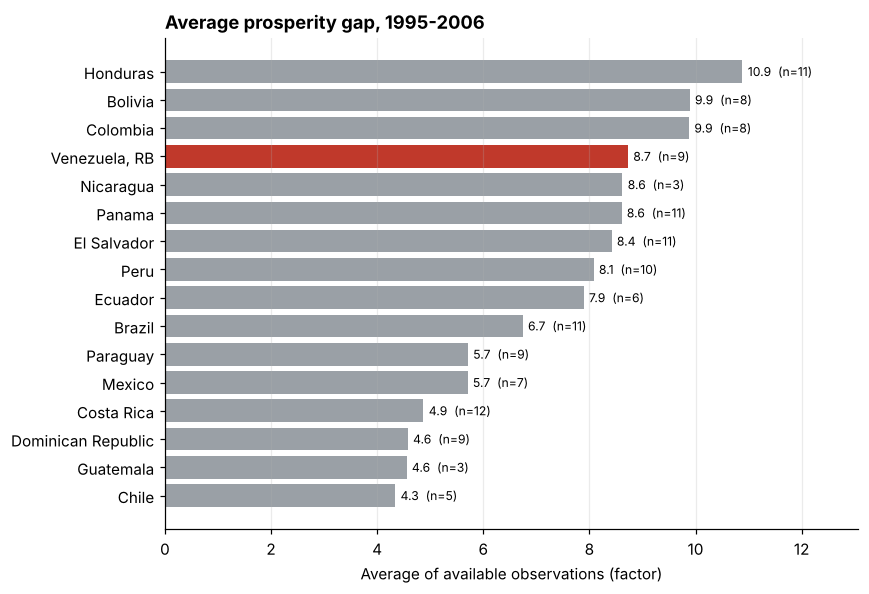

In [14]:
# 1995-2006 average by country (only countries with at least 3 observations in the window)
window = lat[lat["year"].between(1995, 2006)]
ranking = (window.groupby("country")
           .agg(average=("prosperity_gap", "mean"), observations=("year", "count"))
           .query("observations >= 3")
           .sort_values("average"))

fig, ax = plt.subplots(figsize=(8, 5.5))
colors = [RED if c.startswith("Venezuela") else GREY for c in ranking.index]
ax.barh(ranking.index, ranking["average"], color=colors)
for i, (avg, n) in enumerate(zip(ranking["average"], ranking["observations"])):
    ax.text(avg + 0.1, i, f"{avg:.1f}  (n={n})", va="center", fontsize=8)
ax.set_title("Average prosperity gap, 1995-2006", loc="left", fontweight="bold")
ax.set_xlabel("Average of available observations (factor)")
ax.set_xlim(0, ranking["average"].max() * 1.2)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig(IMAGES / "03_ranking_1995_2006.png", bbox_inches="tight")
plt.show()

pos = list(ranking.index).index("Venezuela, RB")
print(f"Venezuela ranks {len(ranking) - pos} of {len(ranking)} (1 = largest gap)")
print(f"Regional average (excluding Venezuela): {ranking.drop('Venezuela, RB')['average'].mean():.1f}")

## 5. Conclusions and limitations

### Key findings

1. **Venezuela started well below the regional average.** In 1981 its gap was 4.1, versus 7.3 for Latin America and the Caribbean (LAC). Note: the 1981 and 1987 observations are `group` data, which is less precise than survey microdata.
2. **It converged with the region by 1999.** That year Venezuela (7.8) and LAC (7.8) were practically identical.
3. **It deteriorated sharply until 2003.** Between 1999 and 2003 the gap rose **47.8%** to **11.5**, almost 5 points above the regional average (6.6). That is the highest value among the 12 countries in the sample with data for 2003, although Honduras (11.4) was virtually tied.
4. **It fell sharply between 2003 and 2006.** The last available data point (2006) is **6.5**, a **43.5%** drop from the peak, but still above the regional average (5.4).
5. **In 1995-2006 Venezuela ranked among the countries with the largest gaps.** Its average was **8.7**, the 4th highest of 16 countries, versus 7.3 for the rest of the region.
6. **There is no data after 2006.** Meanwhile, the regional average fell from 5.4 to **3.1** by 2024. This dataset cannot tell us whether Venezuela followed that improvement.

### Limitations
- **Limited data:** only 13 observations, between 1981 and 2006.
- **Comparability:** the series is split into 3 spells (1981-1987, 1989-1999 and 2001-2006). Changes within a spell are more reliable than changes across spells.
- **Irregular years:** the 1995-2006 averages are computed over different years for each country (between 3 and 12 observations), so they are an approximation.
- **Descriptive, not causal:** the analysis shows _what_ happened, not _why_. The 2002-2003 peak coincides with a period of severe political and economic crisis, and the 2006 drop with a context of high oil prices; these are contextual hypotheses that this analysis does not test.
- **Unit:** the file labels the indicator as "Percentage", but the official definition is a multiplicative factor.

### Next steps
- Add other PIP indicators (extreme poverty, Gini coefficient) for a fuller picture.
- Complement with sources covering recent years, such as the ENCOVI survey or ECLAC statistics.
- Build an interactive dashboard (Power BI or Tableau) with these results.